# Una red recurrente simple para pronosticar una serie de tiempo (PyTorch)

En la presentación **La red recurrente** vimos que una red densa no sabe en qué orden llegan los valores de una serie, y que la **neurona recurrente** lo resuelve: lee un valor por paso y guarda una memoria, el **estado oculto** $h_t$, que pasa al paso siguiente:

$$h_t = \tanh\big(w_x\,x_t + w_h\,h_{t-1} + w_0\big)$$

En este notebook llevamos esa idea a código, usando **solo** una red recurrente simple (`nn.RNN` de PyTorch), con un problema real: **pronosticar cuántas personas tomarán el metro de Chicago mañana**, a partir de lo que pasó en las últimas ocho semanas. Es el ejemplo del capítulo de redes recurrentes del libro guía del curso (*Hands-On Machine Learning with Scikit-Learn and PyTorch*, de Aurélien Géron).

El recorrido sigue el de la presentación:

1. Cargar la serie y verla.
2. Convertirla en ejemplos de entrenamiento con **ventanas**.
3. Una **neurona** recurrente: comprobar a mano que `nn.RNN` calcula la ecuación de arriba.
4. Una **capa** con muchas neuronas: qué entrega y cuántos parámetros tiene.
5. La **red** completa (capa recurrente + capa densa) y su entrenamiento.
6. Varias capas recurrentes, una encima de otra.
7. Evaluación en datos que la red nunca vio, frente a un pronóstico ingenuo.

## Etapa 1: Se carga la base de datos.

In [1]:
import copy
import tarfile
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset
import matplotlib.pyplot as plt
from tqdm import tqdm

torch.manual_seed(42)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Dispositivo:", device)

Dispositivo: cuda


Los datos son los **abordajes diarios** del sistema de transporte de Chicago (CTA, *Chicago Transit Authority*), publicados por la ciudad en su portal de datos abiertos. Descargamos la copia que usa el libro de Géron:

In [2]:
data_dir = Path("data")
csv_path = data_dir / "ridership" / "CTA_-_Ridership_-_Daily_Boarding_Totals.csv"
if not csv_path.exists():
    data_dir.mkdir(exist_ok=True)
    tgz_path, _ = urllib.request.urlretrieve("https://github.com/ageron/data/raw/main/ridership.tgz",
                                             data_dir / "ridership.tgz")
    with tarfile.open(tgz_path) as f:
        f.extractall(data_dir)

df = pd.read_csv(csv_path, parse_dates=["service_date"], date_format="%m/%d/%Y")
df.columns = ["date", "day_type", "bus", "rail", "total"]
df = df.sort_values("date").set_index("date")
df = df.drop_duplicates()          # el archivo trae algunos días repetidos
rail = df["rail"]                  # solo nos interesa el metro
rail.head()

/tmp/ipykernel_284174/1785031804.py:8: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  f.extractall(data_dir)


date
2001-01-01    126455
2001-01-02    501952
2001-01-03    536432
2001-01-04    550011
2001-01-05    557917
Name: rail, dtype: int64

Cada valor es el número de personas que abordaron el metro ese día. Es una **serie de tiempo**: una lista de valores de una misma variable medidos uno tras otro (aquí, uno por día), donde **el orden importa**. Veamos unos meses de 2019:

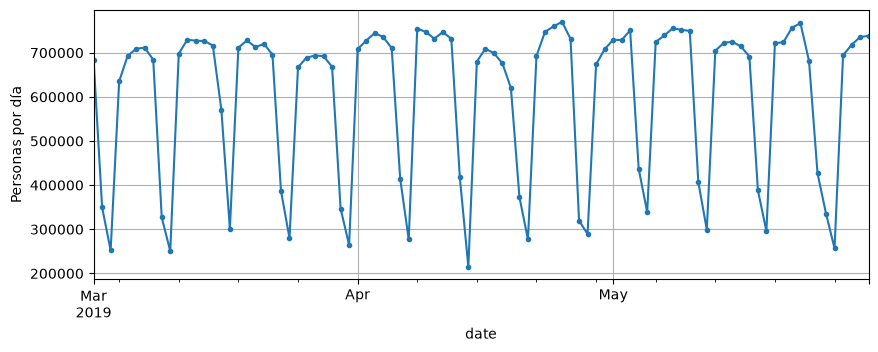

In [3]:
rail["2019-03":"2019-05"].plot(grid=True, marker=".", figsize=(10, 3.5))
plt.ylabel("Personas por día")
plt.show()

Se ve un patrón que se repite **cada 7 días**: muchos pasajeros entre semana y muchos menos el fin de semana. Para pronosticar bien el día siguiente, la red tiene que "recordar" en qué punto de la semana va: justo lo que hace la memoria $h_t$ de una red recurrente.

## Etapa 2: De la serie a ejemplos de entrenamiento: ventanas

Como en la presentación, armamos los ejemplos con una **ventana deslizante**: tomamos $T$ días seguidos como entrada y el día siguiente como etiqueta; luego corremos la ventana un día y repetimos.

```
días:      d1  d2  d3 ... d56 | d57       ← ejemplo 1
               d2  d3 ... d56   d57 | d58 ← ejemplo 2
```

Usamos $T = 56$ días (8 semanas), suficientes para ver varias veces el patrón semanal.

Dividimos el tiempo en tres bloques **sin mezclar el orden**: entrenamos con 2016–2018, validamos con enero–mayo de 2019 y dejamos junio–diciembre de 2019 como prueba. En series de tiempo nunca se mezclan los días al azar para dividir: el modelo no puede "ver el futuro" al entrenar. (Los datos siguen después, pero en 2020 la pandemia hizo caer los viajes a una fracción de lo normal y ningún modelo entrenado con años normales puede anticiparlo, así que no lo usamos.)

Además, dividimos los valores entre un millón para que queden cerca de 1: las redes aprenden mejor con números pequeños.

In [4]:
rail_train = torch.tensor(rail["2016-01":"2018-12"].values / 1e6, dtype=torch.float32)
rail_valid = torch.tensor(rail["2019-01":"2019-05"].values / 1e6, dtype=torch.float32)
rail_test = torch.tensor(rail["2019-06":"2019-12"].values / 1e6, dtype=torch.float32)
print(len(rail_train), len(rail_valid), len(rail_test))

1096 151 214


La clase `WindowDataset` entrega una ventana por índice. La forma de cada entrada es `(T, 1)`: **(pasos de tiempo, valores por paso)**. Aquí hay un solo valor por paso (los pasajeros de ese día). Con un minibatch la forma queda `(batch, T, 1)`, que es lo que espera `nn.RNN` cuando usamos `batch_first=True`.

In [5]:
class WindowDataset(Dataset):
    def __init__(self, series, window_length):
        self.series = series
        self.window_length = window_length

    def __len__(self):
        return len(self.series) - self.window_length

    def __getitem__(self, idx):
        end = idx + self.window_length
        window = self.series[idx:end].unsqueeze(-1)  # (T, 1)
        target = self.series[end:end + 1]            # el día siguiente
        return window, target


window_length = 56
train_set = WindowDataset(rail_train, window_length)
# Para validar y probar, la primera ventana necesita los 56 días anteriores: los pegamos al inicio
valid_set = WindowDataset(torch.cat([rail_train[-window_length:], rail_valid]), window_length)
test_set = WindowDataset(torch.cat([rail_valid[-window_length:], rail_test]), window_length)

train_loader = DataLoader(train_set, batch_size=32, shuffle=True)
valid_loader = DataLoader(valid_set, batch_size=32)
test_loader = DataLoader(test_set, batch_size=32)

x, y = next(iter(train_loader))
print("Entrada:", tuple(x.shape), " Etiqueta:", tuple(y.shape))

Entrada: (32, 56, 1)  Etiqueta: (32, 1)


Mezclar (`shuffle=True`) las **ventanas** de entrenamiento sí está permitido: cada ventana conserva su orden interno; lo que se mezcla es el orden en que la red las ve.

## Etapa 3: Una neurona recurrente

Empecemos con lo más pequeño posible: una capa `nn.RNN` con **una sola neurona** (`hidden_size=1`) que recibe **un valor por paso** (`input_size=1`). Sus parámetros son los de la ecuación de la presentación:

| En la ecuación | En PyTorch |
|---|---|
| $w_x$ (peso de la entrada) | `weight_ih_l0` (*input → hidden*, capa 0) |
| $w_h$ (peso de la memoria) | `weight_hh_l0` (*hidden → hidden*, capa 0) |
| $w_0$ (sesgo) | `bias_ih_l0 + bias_hh_l0` |

PyTorch guarda **dos** sesgos, uno junto a cada peso, pero como siempre se suman, en la práctica hacen lo mismo que el único $w_0$ de la ecuación.

In [6]:
torch.manual_seed(0)
neuron = nn.RNN(input_size=1, hidden_size=1, batch_first=True)
for name, param in neuron.named_parameters():
    print(f"{name:14s} {param.item(): .4f}")

weight_ih_l0   -0.0075
weight_hh_l0    0.5364
bias_ih_l0     -0.8230
bias_hh_l0     -0.7359


Ahora le damos los primeros 4 días de la serie y comparamos lo que devuelve `nn.RNN` con lo que calculamos a mano, paso a paso, con la ecuación (empezando con $h_0 = 0$, como en la presentación).

`nn.RNN` devuelve dos cosas:
- `outputs`: el estado oculto en **cada** paso, $h_1, h_2, \dots, h_T$. Forma `(batch, T, neuronas)`.
- `h_last`: solo el estado del **último** paso, $h_T$. Forma `(capas, batch, neuronas)`.

In [7]:
x4 = rail_train[:4].reshape(1, 4, 1)          # 1 ventana, 4 pasos, 1 valor por paso
outputs, h_last = neuron(x4)

# La misma cuenta, a mano, con la ecuación de la presentación
w_x = neuron.weight_ih_l0.item()
w_h = neuron.weight_hh_l0.item()
w_0 = (neuron.bias_ih_l0 + neuron.bias_hh_l0).item()

h = 0.0                                         # h_0 = 0
for t in range(4):
    x_t = x4[0, t, 0].item()
    h = np.tanh(w_x * x_t + w_h * h + w_0)      # h_t = tanh(w_x x_t + w_h h_{t-1} + w_0)
    print(f"paso {t + 1}: x_t = {x_t:.3f}   h_t a mano = {h: .4f}   h_t de nn.RNN = {outputs[0, t, 0].item(): .4f}")

print("\nÚltimo estado h_last:", round(h_last.item(), 4))

paso 1: x_t = 0.320   h_t a mano = -0.9156   h_t de nn.RNN = -0.9156
paso 2: x_t = 0.366   h_t a mano = -0.9676   h_t de nn.RNN = -0.9676
paso 3: x_t = 0.288   h_t a mano = -0.9693   h_t de nn.RNN = -0.9693
paso 4: x_t = 0.703   h_t a mano = -0.9695   h_t de nn.RNN = -0.9695

Último estado h_last: -0.9695


Coinciden: `nn.RNN` no hace nada más que aplicar esa ecuación una vez por paso, **con los mismos pesos** en todos los pasos, y pasar el resultado al paso siguiente. El último estado, $h_T$, es el "resumen" de toda la ventana que construyó la neurona al leerla día a día.

## Etapa 4: Una capa con muchas neuronas

Una sola neurona guarda su memoria en un único número: es poco. Como vimos en la presentación, se juntan $n$ neuronas en una **capa**; ahora la memoria es un vector $\mathbf{h}_t$ con $n$ valores, y cada neurona recibe la entrada $x_t$ y la memoria de **todas** las neuronas en el paso anterior:

$$\mathbf{h}_t = \tanh\big(W_x\,x_t + W_h\,\mathbf{h}_{t-1} + \mathbf{w}_0\big)$$

En PyTorch solo cambia `hidden_size`. Pasemos un minibatch de ventanas por una capa de 32 neuronas y miremos las formas:

In [8]:
layer = nn.RNN(input_size=1, hidden_size=32, batch_first=True)
outputs, h_last = layer(x)
print("Entrada x:    ", tuple(x.shape), "  (batch, T, valores por paso)")
print("outputs:      ", tuple(outputs.shape), " (batch, T, neuronas): h_t en cada paso")
print("h_last:       ", tuple(h_last.shape), " (capas, batch, neuronas): solo h_T")
print("¿outputs[:, -1] es h_last?", torch.allclose(outputs[:, -1], h_last[0]))

Entrada x:     (32, 56, 1)   (batch, T, valores por paso)
outputs:       (32, 56, 32)  (batch, T, neuronas): h_t en cada paso
h_last:        (1, 32, 32)  (capas, batch, neuronas): solo h_T
¿outputs[:, -1] es h_last? True


¿Cuántos parámetros tiene la capa? Con $d$ valores por paso y $n$ neuronas:

- $W_x$: $n \times d$ pesos (cada neurona mira la entrada).
- $W_h$: $n \times n$ pesos (cada neurona mira la memoria de todas).
- Sesgos: $n$ en la ecuación ($2n$ en PyTorch, por los dos sesgos que se suman).

Y, como en la actividad de la presentación, **no dependen de $T$**: los mismos pesos se usan en cada paso, así que la capa acepta ventanas de cualquier largo.

In [9]:
d, n = 1, 32
n_params = sum(p.numel() for p in layer.parameters())
print(f"Parámetros de la capa: {n_params}  (n·d + n·n + 2n = {n*d + n*n + 2*n})")

for T in (7, 56, 365):
    out, _ = layer(torch.randn(1, T, 1))
    print(f"Ventana de T = {T:3d} días → outputs {tuple(out.shape)}, mismos {n_params} parámetros")

Parámetros de la capa: 1120  (n·d + n·n + 2n = 1120)
Ventana de T =   7 días → outputs (1, 7, 32), mismos 1120 parámetros
Ventana de T =  56 días → outputs (1, 56, 32), mismos 1120 parámetros
Ventana de T = 365 días → outputs (1, 365, 32), mismos 1120 parámetros


## Etapa 5: La red completa y su entrenamiento

Para pronosticar el día siguiente necesitamos **un solo número**. La red queda así:

1. Una capa `nn.RNN` lee la ventana día a día.
2. Nos quedamos con el estado del **último** paso, `outputs[:, -1]`: el resumen de las 8 semanas.
3. Una capa densa `nn.Linear` convierte ese resumen de 32 valores en el pronóstico.

¿Por qué no usar directamente el estado oculto como pronóstico? Porque `tanh` limita sus valores a $[-1, 1]$ y tendríamos que usar una sola neurona. La capa densa final deja que la red tenga muchas neuronas recurrentes y aun así entregue un número sin límites.

Primero la red, `RNNNet` (un `nn.Module`, como en notebooks anteriores). El parámetro `num_layers` nos servirá en la Etapa 6 para apilar capas.

In [10]:
class RNNNet(nn.Module):
    def __init__(self, input_size=1, hidden_size=32, num_layers=1):
        super().__init__()
        self.rnn = nn.RNN(input_size=input_size, hidden_size=hidden_size,
                          num_layers=num_layers, batch_first=True)
        self.head = nn.Linear(hidden_size, 1)

    def forward(self, X):
        outputs, _ = self.rnn(X)          # (batch, T, hidden_size)
        last_state = outputs[:, -1]       # h_T: estado tras leer el último día
        return self.head(last_state)      # (batch, 1)

Ahora la clase `RidershipForecaster`, con la misma organización de los notebooks anteriores: arma la red en `__init__` y tiene `train_epoch`, `evaluate`, `fit` y `predict`. Lo nuevo es que se trata de **regresión** (predecimos un número, no una clase):

- **Pérdida:** `nn.HuberLoss`, que se comporta como el error cuadrático para errores pequeños y como el error absoluto para errores grandes, así un día atípico (un festivo) no domina el entrenamiento.
- **Métrica:** el **MAE** (*mean absolute error*, error absoluto medio), en personas por día (multiplicamos por un millón para deshacer la escala).
- **Guardar el mejor modelo:** el entrenamiento de una red recurrente es "nervioso" (el error de validación sube y baja), así que al final de cada época guardamos los pesos si son los mejores hasta ahora, y al terminar `fit` nos quedamos con ellos.

In [11]:
class RidershipForecaster:
    def __init__(self, hidden_size=32, num_layers=1, lr=3e-3):
        # La red se arma dentro de la clase
        self.net = RNNNet(hidden_size=hidden_size, num_layers=num_layers).to(device)
        self.loss_fn = nn.HuberLoss()
        self.optimizer = torch.optim.Adam(self.net.parameters(), lr=lr)
        self.scale = 1e6  # para reportar el MAE en personas por día
        self.history = {"loss": [], "mae": [], "val_loss": [], "val_mae": []}

    def train_epoch(self, loader):
        # Una época: recorre todos los minibatches y actualiza los pesos
        self.net.train()
        total_loss, total_abs, n = 0.0, 0.0, 0
        for X, y in loader:
            X, y = X.to(device), y.to(device)
            y_pred = self.net(X)
            loss = self.loss_fn(y_pred, y)
            self.optimizer.zero_grad()
            loss.backward()
            self.optimizer.step()
            total_loss += loss.item() * len(X)
            total_abs += (y_pred - y).abs().sum().item()
            n += y.numel()
        return total_loss / len(loader.dataset), total_abs / n * self.scale

    def evaluate(self, loader):
        # Mide el desempeño sin entrenar (sin calcular gradientes)
        self.net.eval()
        total_loss, total_abs, n = 0.0, 0.0, 0
        with torch.no_grad():
            for X, y in loader:
                X, y = X.to(device), y.to(device)
                y_pred = self.net(X)
                total_loss += self.loss_fn(y_pred, y).item() * len(X)
                total_abs += (y_pred - y).abs().sum().item()
                n += y.numel()
        return total_loss / len(loader.dataset), total_abs / n * self.scale

    def fit(self, train_loader, valid_loader, epochs=100):
        best_mae, best_state = float("inf"), None
        pbar = tqdm(range(epochs), desc="Entrenamiento", unit="época")
        for epoch in pbar:
            loss, mae = self.train_epoch(train_loader)
            val_loss, val_mae = self.evaluate(valid_loader)
            for key, value in zip(self.history, (loss, mae, val_loss, val_mae)):
                self.history[key].append(value)
            if val_mae < best_mae:  # guardamos los mejores pesos
                best_mae, best_state = val_mae, copy.deepcopy(self.net.state_dict())
            pbar.set_postfix(mae=f"{mae:,.0f}", val_mae=f"{val_mae:,.0f}", mejor_val_mae=f"{best_mae:,.0f}")
        self.net.load_state_dict(best_state)  # nos quedamos con los mejores pesos
        print(f"Mejor MAE de validación: {best_mae:,.0f}")
        return best_mae

    def predict(self, X):
        # Devuelve el pronóstico (en la escala de entrenamiento) para cada ventana
        self.net.eval()
        with torch.no_grad():
            return self.net(X.to(device)).cpu()

Lo nuevo en el entrenamiento está en `loss.backward()`: como vimos en la presentación, la red desenrollada es una cadena con una copia de la misma celda por día, y el backward la recorre **del último día al primero** (*backward a través del tiempo*). PyTorch lo hace solo; el ciclo de entrenamiento es el mismo de siempre.

Entrenamos una red de una capa con 32 neuronas:

In [12]:
torch.manual_seed(42)
rnn_forecaster = RidershipForecaster(hidden_size=32)
rnn_mae = rnn_forecaster.fit(train_loader, valid_loader, epochs=100)
print(f"Equivale al {rnn_mae / rail['2019-01':'2019-05'].mean():.1%} del promedio diario de validación")

Entrenamiento: 100%|██████████| 100/100 [00:03<00:00, 29.83época/s, mae=144,885, mejor_val_mae=45,469, val_mae=141,405]


Mejor MAE de validación: 45,469
Equivale al 7.8% del promedio diario de validación


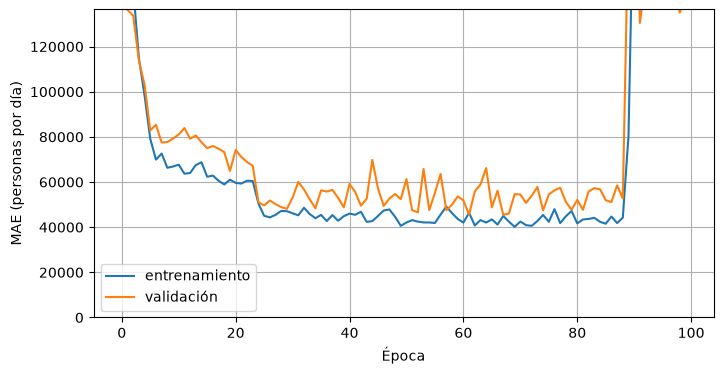

In [13]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(rnn_forecaster.history["mae"], label="entrenamiento")
ax.plot(rnn_forecaster.history["val_mae"], label="validación")
ax.set_ylim(0, 3 * rnn_mae)
ax.set_xlabel("Época"); ax.set_ylabel("MAE (personas por día)"); ax.grid(); ax.legend()
plt.show()

Observen cómo el MAE de validación sube y baja de una época a otra: por eso guardamos el mejor modelo y no el de la última época.

## Etapa 6: Varias capas recurrentes

Como vimos en la presentación, las capas recurrentes se pueden **apilar**: lo que calcula la primera capa en cada paso, $\mathbf{h}_t^{(1)}$, es la entrada de la segunda. En PyTorch basta con `num_layers=2`. Entrenamos con la misma configuración y comparamos:

In [14]:
torch.manual_seed(42)
deep_forecaster = RidershipForecaster(hidden_size=32, num_layers=2)
deep_mae = deep_forecaster.fit(train_loader, valid_loader, epochs=100)

for name, f, mae in [("1 capa ", rnn_forecaster, rnn_mae), ("2 capas", deep_forecaster, deep_mae)]:
    n_params = sum(p.numel() for p in f.net.parameters())
    print(f"{name}: {n_params:5,} parámetros, MAE de validación {mae:,.0f}")

Entrenamiento: 100%|██████████| 100/100 [00:03<00:00, 28.89época/s, mae=41,968, mejor_val_mae=43,951, val_mae=65,205]


Mejor MAE de validación: 43,951
1 capa : 1,153 parámetros, MAE de validación 45,469
2 capas: 3,265 parámetros, MAE de validación 43,951


La segunda capa duplica de sobra los parámetros. Que mejore o no depende del problema (y cambia un poco en cada ejecución): en una serie tan regular como esta, una capa ya captura casi todo el patrón. Más capas ayudan con patrones más complejos; suelen bastar 2 o 3.

## Etapa 7: Evaluación final en el conjunto de prueba

Elegimos el mejor modelo según la **validación** y solo entonces lo medimos en **prueba** (junio a diciembre de 2019), días que la red nunca vio.

In [15]:
best_name, best, best_val = min([("1 capa", rnn_forecaster, rnn_mae), ("2 capas", deep_forecaster, deep_mae)],
                                key=lambda item: item[2])
_, test_mae = best.evaluate(test_loader)
test_period = slice("2019-06", "2019-12")
print(f"Mejor red: {best_name}")
print(f"MAE de prueba: {test_mae:,.0f} personas por día "
      f"({test_mae / rail[test_period].mean():.1%} del promedio diario)")

Mejor red: 2 capas
MAE de prueba: 37,480 personas por día (6.1% del promedio diario)


¿Es bueno ese error? Un número suelto no lo dice: hay que compararlo con el método más simple posible. Como la serie se repite cada semana, el **pronóstico ingenuo** dice *"mañana viajarán las mismas personas que el mismo día de la semana pasada"* (en pandas, correr la serie 7 días con `shift(7)`). Si la red no le gana, no vale la pena.

In [16]:
naive_forecast = rail.shift(7)
naive_test_mae = (rail[test_period] - naive_forecast[test_period]).abs().mean()
print(f"MAE de prueba de la RNN:     {test_mae:,.0f}")
print(f"MAE de prueba del ingenuo:   {naive_test_mae:,.0f}")

MAE de prueba de la RNN:     37,480
MAE de prueba del ingenuo:   62,949


Veamos los pronósticos de la red sobre los primeros meses de prueba, día por día:

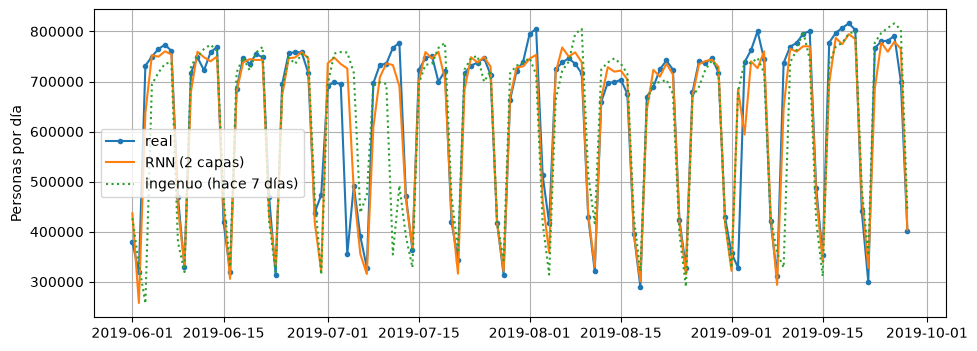

In [17]:
X_test = torch.stack([test_set[i][0] for i in range(len(test_set))])
y_pred = best.predict(X_test).squeeze() * 1e6
dates = rail[test_period].index

n_days = 120
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(dates[:n_days], rail[test_period].values[:n_days], marker=".", label="real")
ax.plot(dates[:n_days], y_pred[:n_days], label=f"RNN ({best_name})")
ax.plot(dates[:n_days], naive_forecast[test_period].values[:n_days], ls=":", label="ingenuo (hace 7 días)")
ax.set_ylabel("Personas por día"); ax.grid(); ax.legend()
plt.show()

La red sigue bien el patrón semanal sin que nadie le dijera que la semana tiene 7 días: lo aprendió leyendo las ventanas día a día y llevando la cuenta en su memoria $h_t$. Donde más falla es en los días atípicos (por ejemplo, el 4 de julio, día de la independencia en Estados Unidos), que no siguen el patrón. Aun así se recupera más rápido que el pronóstico ingenuo, que se equivoca dos veces (el festivo y la semana siguiente), porque la red lee todos los días recientes y no solo uno.

En la siguiente presentación veremos por qué esta red simple **olvida rápido** lo que pasó hace muchos pasos y cómo lo resuelven las celdas **LSTM** y **GRU**; en el notebook que la acompaña las comparamos con esta RNN en el mismo problema.